<a href="https://colab.research.google.com/github/dieynabadiop88-del/Dieynaba_INFO4670_Fall2026/blob/main/INFO4670_Assignment_SMS_Spam_v4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 12: Assignment 4 — SMS Spam Detection

**Goal:** Apply the six-step classification workflow to a real dataset.
Predict whether an SMS message is spam or legitimate (ham) using text-based features.

---

## I. Assignment Objective

By completing this assignment, you will:
- Follow a complete classification pipeline on real-world data
- Engineer binary features from raw text
- Train and evaluate a Decision Tree and a Naive Bayes classifier
- Interpret a confusion matrix and choose the right evaluation metric
- Analyze model performance and reflect on possible improvements

---

## II. Dataset

**Source:** UCI SMS Spam Collection (5,572 real SMS messages, no login required)

| Column | Description | Example |
|---|---|---|
| `label` | Class label | `spam` or `ham` |
| `message` | Raw SMS text | "WINNER!! You have been selected..." |
| `spam` | Encoded label (1 = spam, 0 = ham) | 1 |

Load it with one line — no file upload needed:
```python
url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00228/smsspamcollection.zip'
```

---

## III. Grading Rubric (Total = 70 points)

| Section | What is graded | Points |
|---|---|---|
| Step 1 — Problem definition | Q1a + Q1b + Q1c (written) | 5 |
| Step 2 — Explore the data | Code runs correctly (2B, 2C, 2D) | 10 |
| Step 3 — Feature engineering | Code (3B, 3C) + Q3a + Q3b + Q3c (written) | 15 |
| Step 4 — Split the data | Code (4A) + Q4a + Q4b (written) | 5 |
| Step 5 — Train models | Code: 5A + 5B + 5C + 5D (3 pts each) | 12|
| Step 6 — Code (6A + 6B + 6C) | Each code block runs correctly (4 pts each) | 12 |
| Step 6 — Written (Q6a–Q6d) | Q6a (2) + Q6b (3) + Q6c (3) + Q6d (3) | 11 |
| **Total** | | **70** |

---

## IV. Steps to Complete

Follow the steps below in order.
Each code cell starts with `# Write your code here` — replace it with your implementation.


---
### Setup — Run this cell first (provided)

In [1]:
# This cell is provided — run it before starting
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import re
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.naive_bayes import BernoulliNB
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score,
    recall_score, f1_score, ConfusionMatrixDisplay
)
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
import warnings
warnings.filterwarnings('ignore')
np.random.seed(42)
print('Setup complete!')


Setup complete!


---
## Step 1 — Define the Problem

Before writing any code, answer the questions below.
Your answers here should guide every metric decision you make in Step 6.

**Context:**
A mobile carrier wants an automated classifier to flag spam SMS messages
before they reach users. The two possible errors are:

| Error | What happens |
|---|---|
| False Positive | A real (ham) message gets blocked |
| False Negative | A spam message reaches the user |

### Q1 — Problem Definition *(10 points)*

**Q1a.** Which error is more costly in a real spam filter — False Positive or False Negative?
Give one concrete real-world consequence for each.

*Your answer:*
> I believe a False Positive is more costly because it blocks legitimate messages that users may need. For example, someone could miss an important bank verification code or a medical appointment reminder. A False Negative allows a spam message to reach the user, which could expose them to phishing links or scams. Although both errors have consequences, blocking legitimate communication can significantly affect users' trust in the service.

**Q1b.** Based on Q1a, which metric should be your primary evaluation target?
Choose one: **Precision**, **Recall**, or **F1-Score**. Explain why.

*Your answer:*
> I would prioritize Precision because I want to minimize the number of legitimate messages incorrectly classified as spam. A high precision score means that when the model identifies a message as spam, it is more likely to be correct. This is important for maintaining users' trust and preventing important messages from being blocked.

**Q1c.** The spam rate in this dataset is about 13%.
What accuracy would a dummy model that always predicts "ham" achieve?
Is that number still misleading? Why?

*Your answer:*
> A dummy model that always predicts ham would achieve approximately 87% accuracy because about 87% of the messages are legitimate. However, this result is misleading because the model would fail to detect every spam message. Its spam recall would be 0%, meaning it is not useful as a spam detector despite having high accuracy.


---
## Step 2 — Load and Explore the Data

### Step 2A — Load the dataset



In [2]:
import urllib.request, zipfile, io

url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00228/smsspamcollection.zip'
print('Downloading UCI SMS Spam Collection...')
with urllib.request.urlopen(url) as r:
    zf = zipfile.ZipFile(io.BytesIO(r.read()))
    with zf.open('SMSSpamCollection') as f:
        raw = pd.read_csv(f, sep='\t', header=None, names=['label', 'message'])

raw['spam'] = (raw['label'] == 'spam').astype(int)
print(f'Loaded: {len(raw)} messages')
raw.head(6)


Loaded: 5572 messages


,label,message,spam
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0
5,spam,FreeMsg Hey there darling it's been 3 week's n...,1


### Step 2B — Class distribution

**Hint:** Print the count and percentage of spam and ham messages.
Plot a bar chart with spam count in red and ham count in blue.
Also run a dummy model (predict all ham) and print its Accuracy, Recall, and F1.
This proves the Accuracy Trap from Lecture 8.


Class distribution:
  Ham  (0): 4,825  (86.6%)
  Spam (1): 747  (13.4%)

Dummy model (always predict ham):
  Accuracy  = 86.6%  <-- misleadingly high
  Recall    = 0.0%  <-- catches zero spam
  F1-Score  = 0.0%


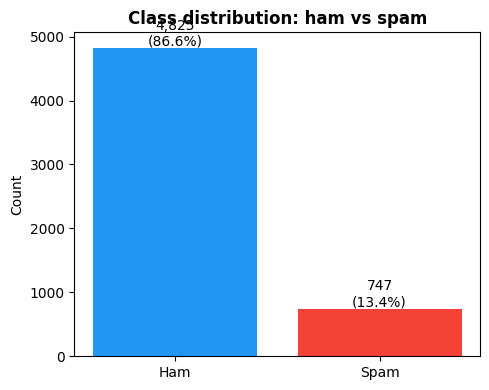

In [3]:
# Write your code here
spam_count = raw['spam'].sum()
ham_count  = (raw['spam'] == 0).sum()
spam_rate  = raw['spam'].mean()

print('Class distribution:')
print(f'  Ham  (0): {ham_count:,}  ({1-spam_rate:.1%})')
print(f'  Spam (1): {spam_count:,}  ({spam_rate:.1%})')
print()

# Prove the accuracy trap with a dummy model
y_all   = raw['spam'].values
y_dummy = np.zeros(len(y_all), dtype=int)
print(f'Dummy model (always predict ham):')
print(f'  Accuracy  = {accuracy_score(y_all, y_dummy):.1%}  <-- misleadingly high')
print(f'  Recall    = {recall_score(y_all, y_dummy, zero_division=0):.1%}  <-- catches zero spam')
print(f'  F1-Score  = {f1_score(y_all, y_dummy, zero_division=0):.1%}')

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(['Ham', 'Spam'], [ham_count, spam_count], color=['#2196F3', '#F44336'])
ax.set_ylabel('Count')
ax.set_title('Class distribution: ham vs spam', fontweight='bold')
for i, v in enumerate([ham_count, spam_count]):
    ax.text(i, v + 30, f'{v:,}\n({v/len(raw):.1%})', ha='center', fontsize=10)
plt.tight_layout()
plt.show()


### Step 2C — Read the raw text

**Hint:** Print 5 spam examples and 5 ham examples.
Limit each message to 130 characters using string slicing.


In [4]:
print('=== SPAM examples ===')
for i, msg in enumerate(raw[raw['spam']==1]['message'].head(5), 1):
    print(f'{i}. {msg[:130]}')
    print()

print('=== HAM examples ===')
for i, msg in enumerate(raw[raw['spam']==0]['message'].head(5), 1):
    print(f'{i}. {msg[:130]}')
    print()


=== SPAM examples ===
1. Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's 

2. FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX std chgs to s

3. WINNER!! As a valued network customer you have been selected to receivea £900 prize reward! To claim call 09061701461. Claim code 

4. Had your mobile 11 months or more? U R entitled to Update to the latest colour mobiles with camera for Free! Call The Mobile Updat

5. SIX chances to win CASH! From 100 to 20,000 pounds txt> CSH11 and send to 87575. Cost 150p/day, 6days, 16+ TsandCs apply Reply HL 

=== HAM examples ===
1. Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...

2. Ok lar... Joking wif u oni...

3. U dun say so early hor... U c already then say...

4. Nah I don't think he goes to usf, he lives around here though

5. Even my b

### Step 2D — Message length analysis

**Hint:** Add a column `msg_length = message.str.len()`.
Print average length for spam and ham.
Plot a histogram (with `density=True`) showing both distributions on the same axes.


Average message length:
  Ham  : 71 characters
  Spam : 139 characters


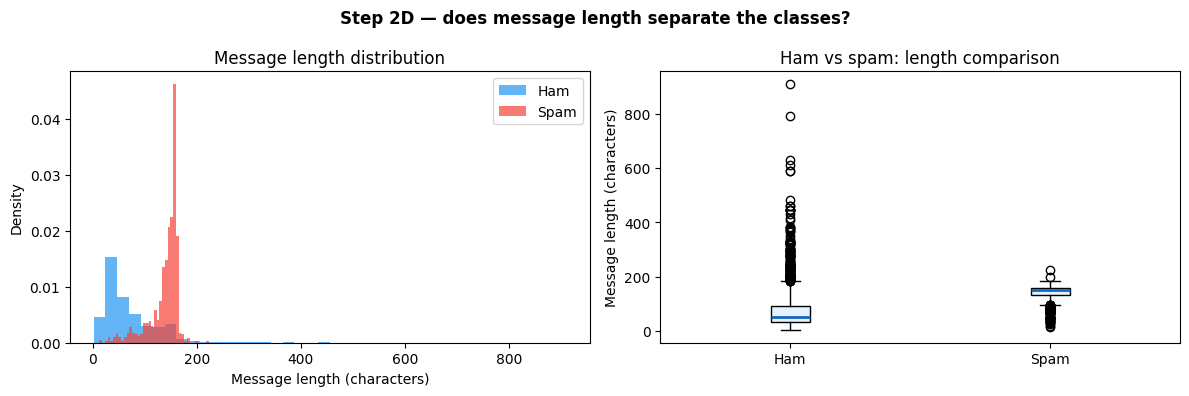

In [5]:
raw['msg_length'] = raw['message'].str.len()

print('Average message length:')
print(f'  Ham  : {raw[raw["spam"]==0]["msg_length"].mean():.0f} characters')
print(f'  Spam : {raw[raw["spam"]==1]["msg_length"].mean():.0f} characters')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(raw[raw['spam']==0]['msg_length'], bins=40, alpha=0.7,
             color='#2196F3', label='Ham', density=True)
axes[0].hist(raw[raw['spam']==1]['msg_length'], bins=40, alpha=0.7,
             color='#F44336', label='Spam', density=True)
axes[0].set_xlabel('Message length (characters)')
axes[0].set_ylabel('Density')
axes[0].set_title('Message length distribution')
axes[0].legend()

axes[1].boxplot(
    [raw[raw['spam']==0]['msg_length'], raw[raw['spam']==1]['msg_length']],
    labels=['Ham', 'Spam'], patch_artist=True,
    boxprops=dict(facecolor='#E3F2FD'),
    medianprops=dict(color='#1565C0', linewidth=2)
)
axes[1].set_ylabel('Message length (characters)')
axes[1].set_title('Ham vs spam: length comparison')
plt.suptitle('Step 2D — does message length separate the classes?', fontweight='bold')
plt.tight_layout()
plt.show()


---

---
## Step 3 — Feature Engineering

Raw text cannot go directly into a classifier.
Convert it into **binary features** (0 or 1) — the same format as the Hands-On Lab.

### Step 3A — Pre-built starter features
This cell is given to you. Run it and study the patterns before adding your own.


In [6]:
# This cell is provided — do not modify it
def build_features(df):
    d = df.copy()
    msg = d['message'].str.lower()

    d['has_phone'] = msg.str.contains(
        r'\b\d{3}[-.]?\d{3}[-.]?\d{4}\b|call.*\d{4,}|\b0\d{9,}\b',
        regex=True).astype(int)

    d['has_money'] = msg.str.contains(
        r'\b(free|win|winner|prize|cash|\$|claim|reward|won)\b',
        regex=True).astype(int)

    d['has_urgency'] = msg.str.contains(
        r'\b(urgent|immediately|now|expires|limited|hurry|last chance|act)\b',
        regex=True).astype(int)

    d['is_long'] = (d['message'].str.len() > 130).astype(int)
    return d

df = build_features(raw)
starter = ['has_phone', 'has_money', 'has_urgency', 'is_long']
print('Starter features (spam vs ham rate):')
print(f'{"Feature":<16} {"Spam%":>7} {"Ham%":>7} {"Gap":>7}')
print('-' * 42)
for f in starter:
    sp = df[df['spam']==1][f].mean()
    ha = df[df['spam']==0][f].mean()
    print(f'{f:<16} {sp:>7.1%} {ha:>7.1%} {sp-ha:>+7.1%}')


Starter features (spam vs ham rate):
Feature            Spam%    Ham%     Gap
------------------------------------------
has_phone          55.2%    0.1%  +55.1%
has_money          52.3%    2.0%  +50.3%
has_urgency        34.9%    6.4%  +28.5%
is_long            76.8%   14.2%  +62.7%


### Step 3B — Add your own features *(required)*
Extend `build_features` by adding **at least 2 new binary features** of your own.

**Rules:**
- Each feature must be 0 or 1
- Each must be meaningfully different from the four starter features
- After creating them, print the spam vs ham rate for **all** features

**Ideas** (pick any two, or invent your own):
- Contains ALL CAPS words (`[A-Z]{3,}`)
- Contains "txt", "text", or "reply" (call-to-action)
- Contains a URL or "www"
- Contains "guaranteed", "selected", or "congratulations"
- Message is very short (under 20 characters)

**Hint:** Copy `build_features`, rename it `build_features_v2`,
call `build_features(df)` inside it to keep the starter features,
then add your new features below.

At the end of the cell, run this line to collect all feature column names:
```python
feature_cols = [c for c in df.columns
                if c not in ['label', 'message', 'spam', 'msg_length']]
```
This variable is used in Steps 4, 5, and 6 — make sure it is defined here.


In [7]:

def build_features_v2(df):
    d = build_features(df)   # keeps all 4 starter features
    msg = d['message'].str.lower()


    # Feature 5: Detect website links
    d['has_url'] = msg.str.contains(
        r'https?://|www\.', regex=True
    ).astype(int)

    # Feature 6: Detect reply instructions
    d['has_reply'] = msg.str.contains(
        r'\b(?:txt|text|reply)\b', regex=True
    ).astype(int)


    return d

df = build_features_v2(raw)

# Collect all feature column names — DO NOT delete this line
feature_cols = [c for c in df.columns
                if c not in ['label', 'message', 'spam', 'msg_length']]

# Print spam vs ham rate for all features
print('All features (spam vs ham rate):')
print(f'{"Feature":<20} {"Spam%":>7} {"Ham%":>7} {"Gap":>7}')
print('-' * 48)
for feat in feature_cols:
    sp = df[df['spam']==1][feat].mean()
    ha = df[df['spam']==0][feat].mean()
    print(f'{feat:<20} {sp:>7.1%} {ha:>7.1%} {sp-ha:>+7.1%}')


All features (spam vs ham rate):
Feature                Spam%    Ham%     Gap
------------------------------------------------
has_phone              55.2%    0.1%  +55.1%
has_money              52.3%    2.0%  +50.3%
has_urgency            34.9%    6.4%  +28.5%
is_long                76.8%   14.2%  +62.7%
has_url                14.2%    0.0%  +14.1%
has_reply              40.7%    2.5%  +38.2%


### Step 3C — Visualize feature gaps

**Hint:** Create one bar chart per feature (use `plt.subplots(1, n_features, ...)`).
Each bar chart shows two bars: spam rate (red) and ham rate (blue).
This is the same chart style used in the Hands-On Lab Step 0.


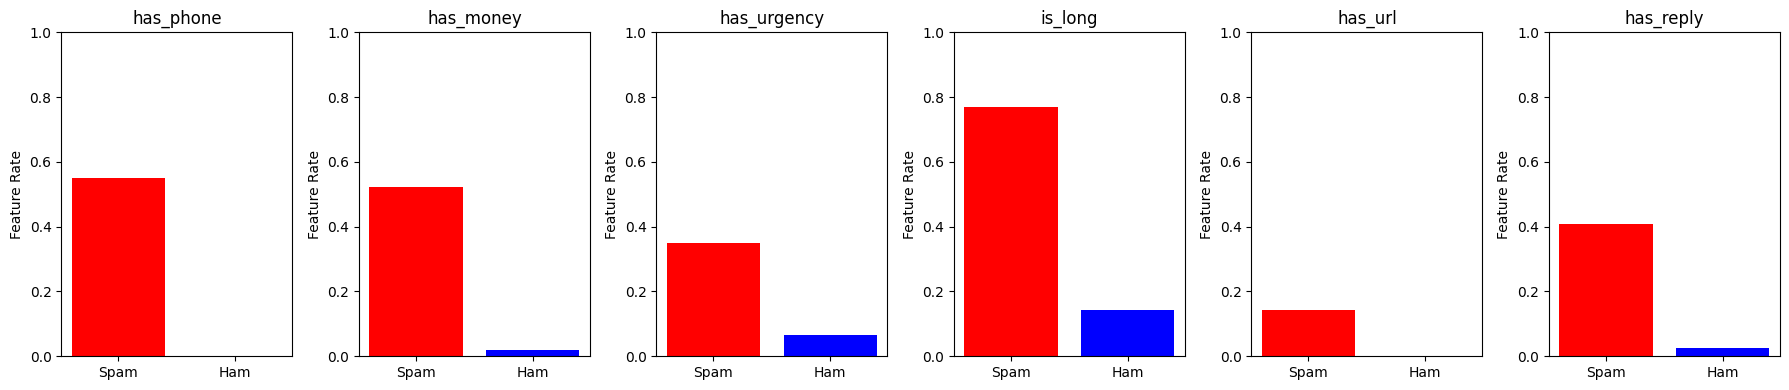

In [8]:
fig, axes = plt.subplots(1, len(feature_cols),
                         figsize=(18, 4))

for ax, feat in zip(axes, feature_cols):
    spam_rate = df[df['spam'] == 1][feat].mean()
    ham_rate = df[df['spam'] == 0][feat].mean()

    ax.bar(['Spam', 'Ham'],
           [spam_rate, ham_rate],
           color=['red', 'blue'])

    ax.set_title(feat)
    ax.set_ylim(0, 1)
    ax.set_ylabel('Feature Rate')

plt.tight_layout()
plt.show()



### Q3 — Feature Engineering *(20 points)*

**Q3a.** Describe the two features you added.
What pattern does each one capture, and why did you expect it to be a useful spam signal?

*Feature 1 — name and explanation: has_url
> The `has_url` feature checks whether a message contains a website link, such as "http," "https," or "www." I chose this feature because spam messages often include links that direct users to suspicious websites or phishing pages. Based on my results, 14.2% of spam messages contained URLs, compared to approximately 0% of legitimate messages. This suggests that URLs can be a useful indicator of spam.

*Feature 2 — name and explanation: has_reply
> The `has_reply` feature detects words such as "txt," "text," or "reply." I selected this feature because spam messages often encourage recipients to respond to claim prizes, receive offers, or participate in promotions. My results showed that 40.7% of spam messages contained these words, compared to only 2.5% of legitimate messages. This makes reply-related language a potentially useful spam indicator.

**Q3b.** Which feature has the largest gap between spam and ham?
Why does a large gap matter when a Decision Tree selects its root node?
Connect your answer to the concept of **Information Gain** from Lecture 8.

*Your answer:*
> The `is_long` feature has the largest gap at approximately 62.7 percentage points. About 76.8% of spam messages are longer than 130 characters, compared to only 14.2% of legitimate messages. This difference matters because a Decision Tree uses Information Gain to determine which feature best separates the classes at each split. A feature that reduces uncertainty about whether a message is spam or ham is more useful for classification. Although `is_long` has the largest gap, the Decision Tree must calculate Information Gain before determining which feature should be the root node.

**Q3c.** Look at the spam examples from Step 2C.
Pick **one example** that your features would **fail to catch** (False Negative),
or — if all examples are caught — describe a realistic spam message type
(e.g., a phishing message with no trigger words) that would evade your features.
State which specific feature(s) fail and explain why.

*Your answer:*
> A possible false negative would be a phishing message that says, "Your account needs verification. Visit the customer portal to confirm your details." This message could be spam, but our features might fail to identify it. It does not contain a phone number, money-related words, urgency keywords from our selected list, a URL, or reply-related words. It is also shorter than 130 characters, so `is_long` would be 0. Since all six features could return 0, the model might classify the message as legitimate even though it is suspicious.


---
## Step 4 — Split the Data

### Step 4A — Train/Test split

**Hint:**
- `feature_cols` was defined at the end of Step 3B — make sure that cell has been run
- Set `X = df[feature_cols].values` and `y = df['spam'].values`
- Use `train_test_split` with `test_size=0.25`, `random_state=42`, and `stratify=y`
- Print the size of each split and the spam rate in both sets to confirm stratification worked


In [9]:

# Select the features and target variable
X = df[feature_cols].values
y = df['spam'].values

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

# Print the size of each set
print("Training set size:", len(X_train))
print("Testing set size:", len(X_test))

# Check spam percentages
print(f"Training spam rate: {y_train.mean():.1%}")
print(f"Testing spam rate: {y_test.mean():.1%}")



Training set size: 4179
Testing set size: 1393
Training spam rate: 13.4%
Testing spam rate: 13.4%


### Q4 — Data Split *(10 points)*

**Q4a. (5 points)** Why do we pass `stratify=y`?
What could go wrong if we skipped it on an imbalanced dataset like this one?

*Your answer:*
> We use `stratify=y` to maintain approximately the same proportion of spam and legitimate messages in both the training and testing datasets. Since only 13.4% of our messages are spam, the dataset is imbalanced. Without stratification, one set could contain too few spam messages, which could affect the model's learning or make its evaluation less reliable. Stratification helps ensure that both sets represent the original class distribution.

**Q4b. (5 points)** We use a 75/25 train/test split.
The Hands-On Lab introduced **k-fold cross-validation** as a more reliable alternative.
Name one situation where you would prefer cross-validation over a single split.

*Your answer:*
> I would prefer k-fold cross-validation when working with a small dataset or when I want a more reliable estimate of model performance. Instead of evaluating the model using only one train/test split, cross-validation divides the data into multiple folds and evaluates the model several times. This reduces the dependence on a single split and helps determine whether the model performs consistently across different subsets of the data.


---
## Step 5 — Train the Models （Each code 5 pts）

### Step 5A — Decision Tree

**Hint:**
- Use `DecisionTreeClassifier(max_depth=4, random_state=42, class_weight='balanced')`
- Fit on the training set
- Print the number of leaves with `.get_n_leaves()`
- Visualize the tree with `plot_tree(..., feature_names=..., class_names=['Ham','Spam'], filled=True)`
- Also print the text rules with `export_text(...)`


Number of leaves: 14


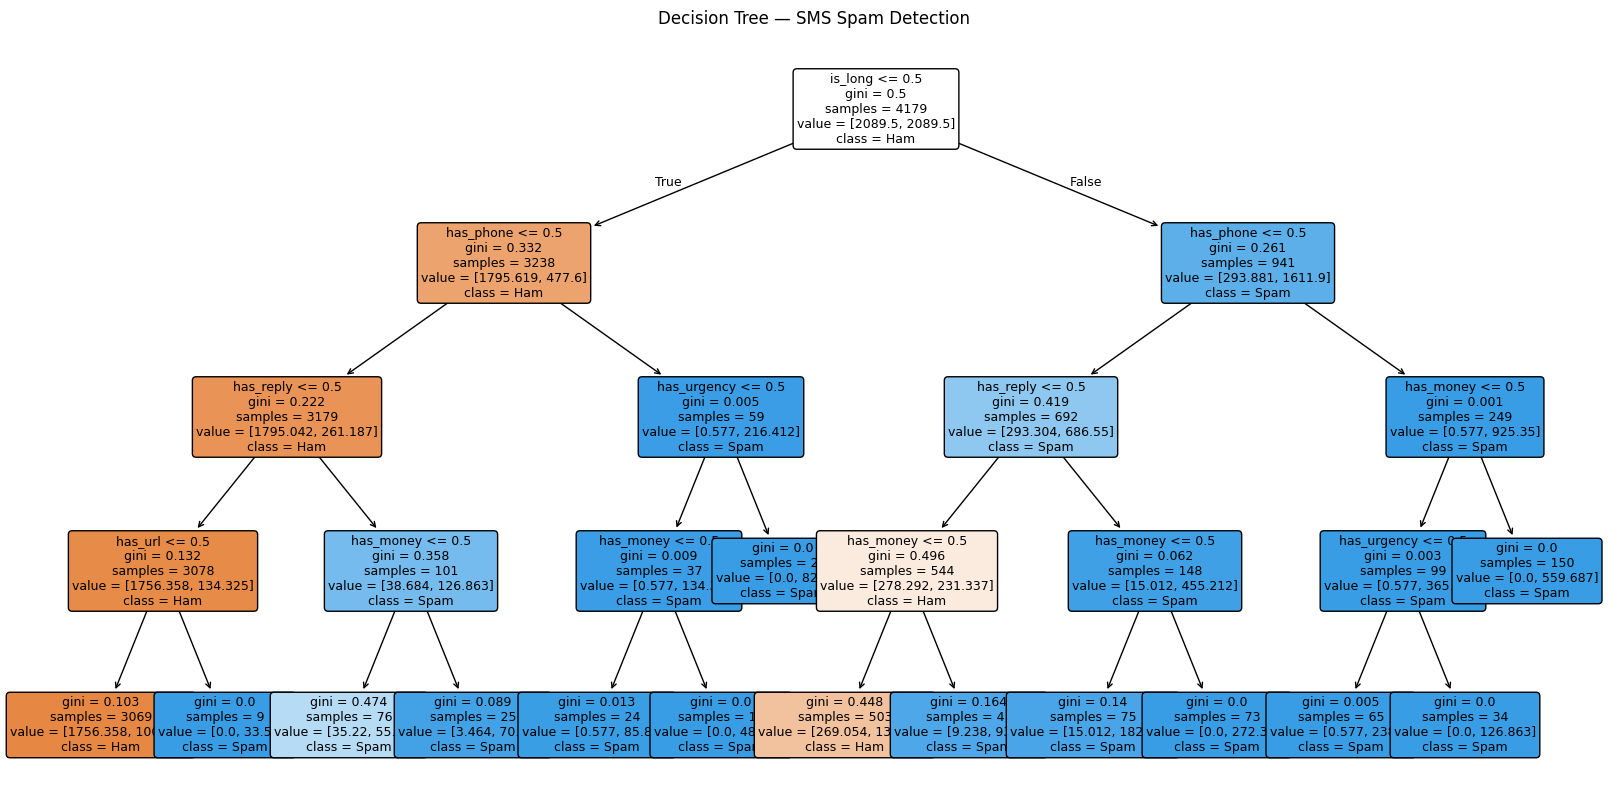

Decision Tree Rules:
|--- is_long <= 0.50
|   |--- has_phone <= 0.50
|   |   |--- has_reply <= 0.50
|   |   |   |--- has_url <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- has_url >  0.50
|   |   |   |   |--- class: 1
|   |   |--- has_reply >  0.50
|   |   |   |--- has_money <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- has_money >  0.50
|   |   |   |   |--- class: 1
|   |--- has_phone >  0.50
|   |   |--- has_urgency <= 0.50
|   |   |   |--- has_money <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- has_money >  0.50
|   |   |   |   |--- class: 1
|   |   |--- has_urgency >  0.50
|   |   |   |--- class: 1
|--- is_long >  0.50
|   |--- has_phone <= 0.50
|   |   |--- has_reply <= 0.50
|   |   |   |--- has_money <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- has_money >  0.50
|   |   |   |   |--- class: 1
|   |   |--- has_reply >  0.50
|   |   |   |--- has_money <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- has_money >  0.50
|   |   |   |   |--- cla

In [10]:
# Create the Decision Tree classifier
dt = DecisionTreeClassifier(
    max_depth=4,
    random_state=42,
    class_weight='balanced'
)

# Train the model
dt.fit(X_train, y_train)

# Print the number of leaves
print("Number of leaves:", dt.get_n_leaves())

# Visualize the Decision Tree
plt.figure(figsize=(20, 10))

plot_tree(
    dt,
    feature_names=feature_cols,
    class_names=['Ham', 'Spam'],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("Decision Tree — SMS Spam Detection")
plt.show()

# Print the decision rules
print("Decision Tree Rules:")
print(export_text(dt, feature_names=feature_cols))


### Step 5B — Feature Importance

**Hint:**
- Get `.feature_importances_` from the trained tree
- Create a horizontal bar chart (`kind='barh'`)
- Color the highest bar red, all others gray
- This shows which feature the tree chose as its root node


is_long: 0.5173
has_phone: 0.2360
has_reply: 0.1707
has_money: 0.0396
has_url: 0.0364
has_urgency: 0.0000


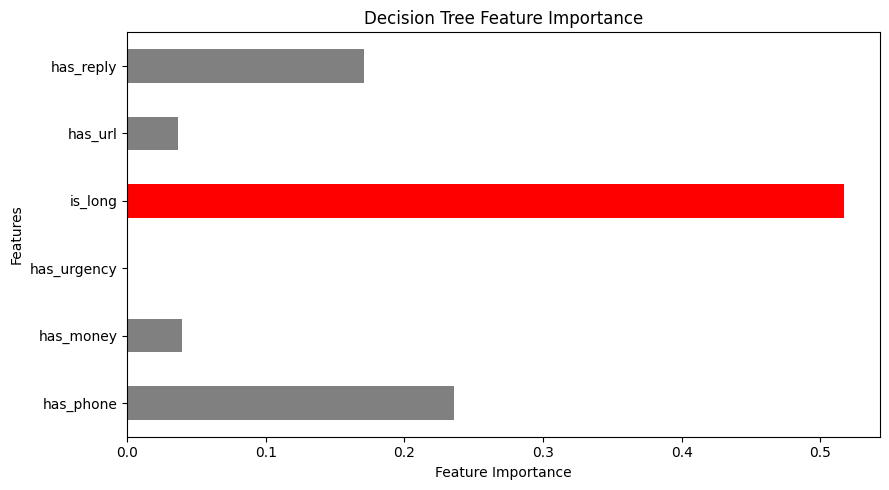

In [11]:
importances = dt.feature_importances_

# Display feature importance scores
for feature, importance in sorted(
    zip(feature_cols, importances),
    key=lambda x: x[1],
    reverse=True
):
    print(f"{feature}: {importance:.4f}")

# Plot feature importance
plt.figure(figsize=(9, 5))

pd.Series(importances, index=feature_cols).plot(
    kind='barh',
    color=['red' if i == importances.argmax() else 'gray'
           for i in range(len(importances))]
)
plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Decision Tree Feature Importance")

plt.tight_layout()
plt.show()



### Step 5C — Effect of Tree Depth

**Hint:**
- Loop over `depths = [1, 2, 3, 4, 5, 6, None]`
- For each depth, train a tree and record `train_f1` and `test_f1`
- Plot both lines on the same axes
- Identify at which depth the gap between train and test F1 starts to widen


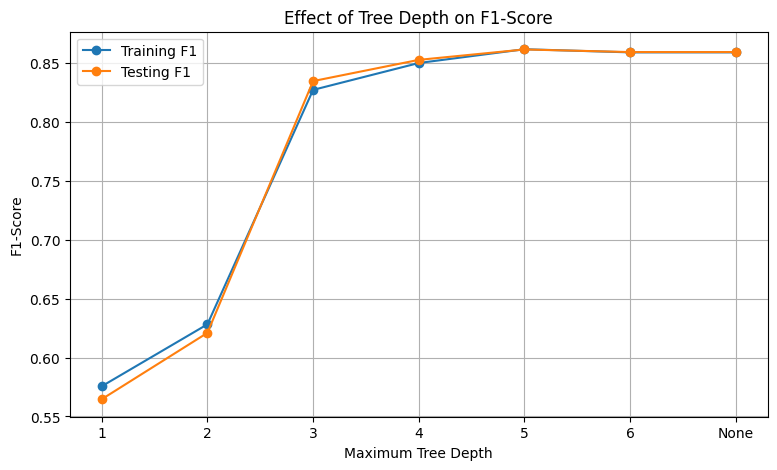

In [12]:
depths = [1, 2, 3, 4, 5, 6, None]
train_f1 = []
test_f1 = []

for depth in depths:
    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42,
        class_weight='balanced'
    )

    model.fit(X_train, y_train)

    train_f1.append(
        f1_score(y_train, model.predict(X_train))
    )

    test_f1.append(
        f1_score(y_test, model.predict(X_test))
    )

# Plot training and testing F1-scores
plt.figure(figsize=(9, 5))
plt.plot(range(len(depths)), train_f1,
         marker='o', label='Training F1')
plt.plot(range(len(depths)), test_f1,
         marker='o', label='Testing F1')

plt.xticks(range(len(depths)),
           [str(d) for d in depths])
plt.xlabel('Maximum Tree Depth')
plt.ylabel('F1-Score')
plt.title('Effect of Tree Depth on F1-Score')
plt.legend()
plt.grid(True)
plt.show()

# The graph shows that both training and testing F1-scores improve as the tree depth increases from 1 to 5.
# At depth 5, the testing F1-score reaches approximately 0.86. After that, performance remains almost unchanged, suggesting that increasing the tree depth does not
# provide much additional improvement. There is no clear sign of overfitting because the training and testing scores remain close to each other.
# Based on these results, depth 5 appears to be a reasonable choice.

### Step 5D — Naive Bayes

**Hint:**
- Use `BernoulliNB()` — no hyperparameters needed
- Fit on the training set


In [13]:
nb = BernoulliNB()

nb.fit(X_train, y_train)

print("Naive Bayes model trained successfully!")


Naive Bayes model trained successfully!


---
## Step 6 — Evaluate *(Each code block 4 points)*

### Step 6A — Confusion Matrices

**Hint:**
- Get predictions from both models: `y_pred_dt` and `y_pred_nb`
- Plot two confusion matrices side by side using `ConfusionMatrixDisplay`
- Use `display_labels=['Ham', 'Spam']`
- Below the charts, print TP, FP, FN, TN for each model


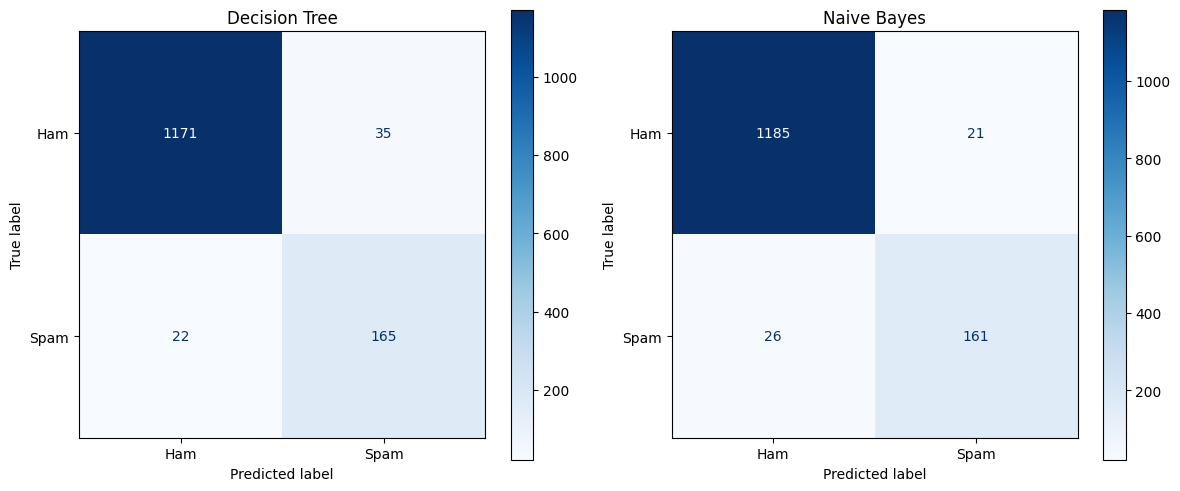

Decision Tree:
TP: 165, FP: 35, FN: 22, TN: 1171

Naive Bayes:
TP: 161, FP: 21, FN: 26, TN: 1185



In [14]:
# Generate predictions
y_pred_dt = dt.predict(X_test)
y_pred_nb = nb.predict(X_test)

# Plot confusion matrices side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, pred, name in zip(
    axes,
    [y_pred_dt, y_pred_nb],
    ['Decision Tree', 'Naive Bayes']
):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        pred,
        display_labels=['Ham', 'Spam'],
        ax=ax,
        cmap='Blues'
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()

# Print TP, FP, FN, TN for each model
for name, pred in [
    ('Decision Tree', y_pred_dt),
    ('Naive Bayes', y_pred_nb)
]:
    tn, fp, fn, tp = confusion_matrix(
        y_test, pred
    ).ravel()

    print(f"{name}:")
    print(f"TP: {tp}, FP: {fp}, FN: {fn}, TN: {tn}")
    print()



### Step 6B — Metrics Comparison

**Hint:**
- Build a DataFrame with columns: Model, Accuracy, Precision, Recall, F1-Score
- One row per model
- Also create a grouped bar chart comparing all four metrics side by side


        Model  Accuracy  Precision  Recall  F1-Score
Decision Tree     0.959      0.825   0.882     0.853
  Naive Bayes     0.966      0.885   0.861     0.873


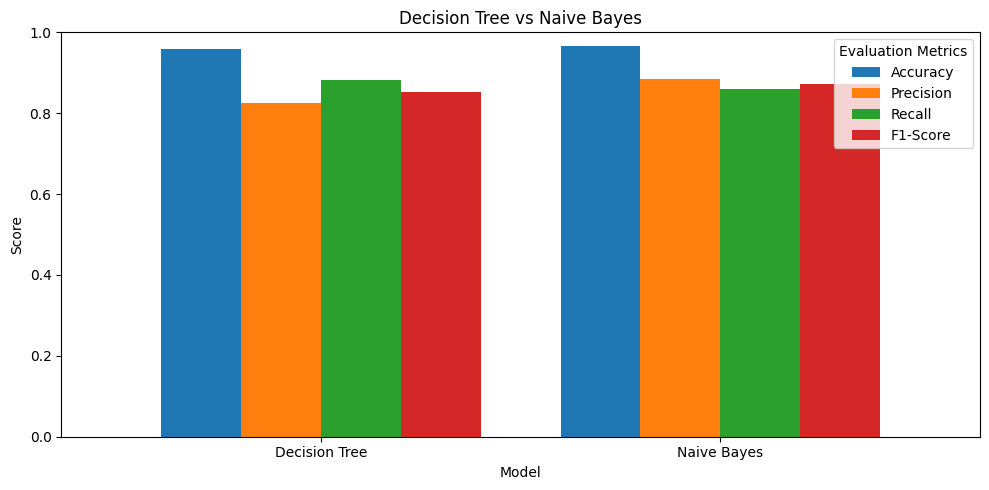

In [15]:

# Create a DataFrame with evaluation metrics
results = pd.DataFrame({
    'Model': ['Decision Tree', 'Naive Bayes'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_nb)
    ],
    'Precision': [
        precision_score(y_test, y_pred_dt),
        precision_score(y_test, y_pred_nb)
    ],
    'Recall': [
        recall_score(y_test, y_pred_dt),
        recall_score(y_test, y_pred_nb)
    ],
    'F1-Score': [
        f1_score(y_test, y_pred_dt),
        f1_score(y_test, y_pred_nb)
    ]
})

# Display the results table
print(results.round(3).to_string(index=False))

# Create a grouped bar chart
results.set_index('Model').plot(
    kind='bar',
    figsize=(10, 5),
    width=0.8
)

plt.title('Decision Tree vs Naive Bayes')
plt.ylabel('Score')
plt.xlabel('Model')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title='Evaluation Metrics')
plt.tight_layout()
plt.show()



### Step 6C — Cross-Validation

**Hint:**
- Use `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`
- Run `cross_val_score` with `scoring='f1'` for both models
- Print the average F1 across 5 folds for each model


In [16]:
# Create stratified 5-fold cross-validation
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Cross-validation for Decision Tree
dt_cv = cross_val_score(
    dt, X_train, y_train,
    cv=skf,
    scoring='f1'
)

# Cross-validation for Naive Bayes
nb_cv = cross_val_score(
    nb, X_train, y_train,
    cv=skf,
    scoring='f1'
)

# Print average F1-scores
print(f"Decision Tree Average F1: {dt_cv.mean():.3f}")
print(f"Naive Bayes Average F1: {nb_cv.mean():.3f}")



Decision Tree Average F1: 0.850
Naive Bayes Average F1: 0.886


### Q6 — Evaluation & Analysis *(25 points)*

> **Points breakdown:**
> - Step 6A code (runs correctly): 4 pts
> - Step 6B code (runs correctly): 4 pts
> - Step 6C code (runs correctly): 4 pts
> - Q6a written: 3 pts
> - Q6b written: 3 pts
> - Q6c written: 4 pts
> - Q6d written: 3 pts
> - **Total: 25 pts**

---

**Q6a. Read the confusion matrices (Step 6A) — *(3 points)***

For each model, state:
- How many spam messages were correctly caught (True Positives)?
- How many spam messages slipped through (False Negatives)?
- How many legitimate messages were wrongly blocked (False Positives)?

*Decision Tree:*
> The Decision Tree correctly identified 165 spam messages (True Positives). However, 22 spam messages were incorrectly classified as legitimate (False Negatives), and 35 legitimate messages were wrongly classified as spam (False Positives).

*Naive Bayes:*
> The Naive Bayes model correctly identified 161 spam messages (True Positives). It missed 26 spam messages (False Negatives) and incorrectly classified 21 legitimate messages as spam (False Positives).

**Q6b. Apply your metric from Q1b — *(3 points)***

Which model wins on the metric you chose in Step 1?
By how much? Does the cross-validation result (Step 6C) confirm this?

*Your answer:*
> I chose Precision in Step 1 because I wanted to minimize the number of legitimate messages incorrectly classified as spam. Naive Bayes performed better, achieving 88.5% precision compared to 82.5% for the Decision Tree, a difference of 6 percentage points. The cross-validation results also support this choice because Naive Bayes achieved an average F1-score of 88.6%, compared to 85.0% for the Decision Tree. Although cross-validation measured F1-score rather than precision directly, it supports Naive Bayes as the stronger overall model.

**Q6c. Recommendation memo — *(4 points)***

Imagine you are presenting to a product manager at a mobile carrier.
Write 4–5 sentences that:
1. State which model you recommend
2. Justify the choice with one specific number from your results
3. Acknowledge one weakness of your recommended model
4. Propose one concrete improvement

*Your memo:*
> I would recommend the Naive Bayes classifier for our mobile carrier's SMS spam detection system. It achieved 88.5% precision and incorrectly blocked only 21 legitimate messages, compared to 35 for the Decision Tree. One weakness is that Naive Bayes missed 26 spam messages, slightly more than the Decision Tree, which missed 22. To improve the model, I would add features that detect suspicious links and phishing-related language, such as account verification requests. This could help the model recognize more spam messages while maintaining high precision.

**Q6d. Generalization — *(3 points)***

The SMS Spam Collection was collected in the early 2010s.
Modern spam often uses professional language and legitimate-looking URLs.
Identify **two features you built** that would likely fail on modern spam, and explain why.

*Your answer:*
> Two features that might fail to detect modern spam are `has_url` and `has_reply`. The `has_url` feature only checks whether a message contains a URL, but modern spam may use legitimate-looking links that are difficult to distinguish from safe websites. It also cannot detect phishing messages that do not include a link. The `has_reply` feature looks for words such as "txt," "text," and "reply," but modern spam often uses professional language without these obvious instructions. As a result, messages that avoid these keywords could be classified as legitimate even when they are fraudulent.
